<a href="https://colab.research.google.com/github/iadityapratapsinghe/Project---i-/blob/main/notebooks/Music%20Genre%20Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/Music Genre Classifier/features_30_sec_with_missing_values.csv'
df = pd.read_csv(file_path)

print(df.head())
print(df.shape)


          filename    length  chroma_stft_mean  chroma_stft_var  rms_mean  \
0  blues.00000.wav  661794.0          0.350088         0.088757  0.130228   
1  blues.00001.wav  661794.0          0.340914         0.094980  0.095948   
2  blues.00002.wav  661794.0          0.363637         0.085275  0.175570   
3  blues.00003.wav  661794.0          0.404785         0.093999  0.141093   
4  blues.00004.wav  661794.0          0.308526         0.087841  0.091529   

    rms_var  spectral_centroid_mean  spectral_centroid_var  \
0  0.002827             1784.165850          129774.064525   
1  0.002373             1530.176679          375850.073649   
2  0.002746             1552.811865          156467.643368   
3  0.006346             1070.106615          184355.942417   
4  0.002303             1835.004266                    NaN   

   spectral_bandwidth_mean  spectral_bandwidth_var  ...  mfcc16_var  \
0              2002.449060            85882.761315  ...   52.420910   
1              2039.03

In [8]:
# Data inspection, Outlier detection, Cleaning and Duplicate removal.

In [9]:
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")

Duplicate rows found: 0


In [10]:
if 'filename' in df.columns:
    df = df.drop(columns=['filename'])

In [11]:
missing_values = df.isnull().sum().sum()
print(f"Total missing values found: {missing_values}")
if missing_values > 0:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
    print("Missing values treated using median imputation.")

Total missing values found: 1714
Missing values treated using median imputation.


Generating Outlier Detection Boxplot...


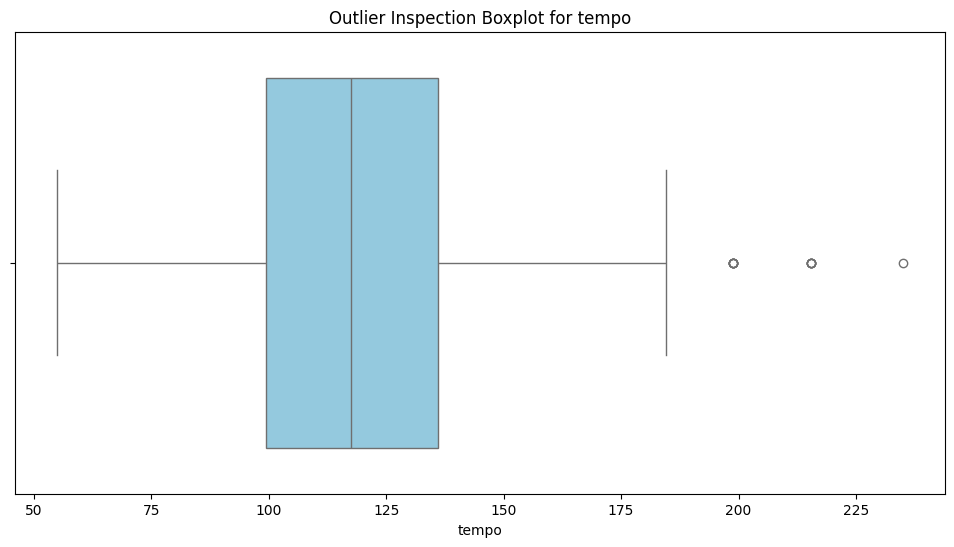

In [12]:
print("Generating Outlier Detection Boxplot...")
plt.figure(figsize=(12, 6))
feature_to_check = 'tempo' if 'tempo' in df.columns else df.select_dtypes(include=[np.number]).columns[0]
sns.boxplot(x=df[feature_to_check], color='skyblue')
plt.title(f"Outlier Inspection Boxplot for {feature_to_check}")
plt.xlabel(feature_to_check)
plt.show()

In [13]:
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Filtering rows within bounds
    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
    return filtered_data

print(f"Cleaned dataset shape after Part 1: {df.shape}")

Cleaned dataset shape after Part 1: (1000, 59)
